# JS09 - Lab 2
## Exact NN vs. FAISS

Pencarian tetangga terdekat memakai **FAISS**. Dua indeks dibandingkan:

* `IndexFlatL2` - pencarian *exact* (brute force) dengan metrik L2, dipakai sebagai *ground truth*.
* `IndexIVFPQ` - pencarian *approximate*: **IVF** (inverted file / clustering) + **PQ** (product quantization).

### Step 1 - Install FAISS

Modul menyebut `faiss-cpu` dan `faiss-gpu`. Pada lingkungan tanpa CUDA (termasuk instalasi Windows
melalui pip) `faiss-gpu` tidak tersedia, sehingga di sini hanya `faiss-cpu` yang dipasang.

In [1]:
!pip install faiss-cpu
# !pip install faiss-gpu   # hanya untuk mesin dengan CUDA

### Step 2 - Import Libraries

In [2]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

### Step 3 - Create a Dummy Dataset

In [3]:
# Build random data
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 data points in 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query point

print("Dataset shape:", X.shape)
print("Query:", query)

Dataset shape: (1000, 2)
Query: [[0.5 0.5]]


### Step 4 - Create Exact NN Model

`IndexFlatL2` menyimpan seluruh vektor apa adanya dan menghitung jarak L2 ke semua vektor
saat query - inilah acuan *ground truth*.

In [4]:
# Search NN using Exact NN
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

# Compute Exact NN Time
start = time.perf_counter()
D_flat, I_flat = index_flat.search(query, 3)  # Find 3 nearest neighbors
end = time.perf_counter()
time_flat = end - start

print("Exact NN indices:", I_flat)
print("Exact NN distances:", D_flat)
print("Exact Time:", time_flat, "s")

Exact NN indices: [[137 170 750]]
Exact NN distances: [[0.00013095 0.00077404 0.00079751]]
Exact Time: 9.18999999157677e-05 s


### Step 5 - Create FAISS Model

`IndexIVFPQ` mempercepat pencarian dengan dua tahap:

* `nlist = 10` - jumlah cluster (inverted list) untuk *coarse quantization*.
* `m = 2` - jumlah subvector; tiap subvector dikodekan 8 bit (256 centroid), sehingga vektor
  disimpan sebagai kode berukuran `m` byte, bukan float 4 byte per dimensi.

In [5]:
# Compute FAISS
nlist = 10   # number of clusters (inverted lists)
m = 2        # number of subvectors
quantizer = faiss.IndexFlatL2(2)   # used by IVF for initial clustering
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bits per subvector

index_ivfpq.train(X)  # train centroids
index_ivfpq.add(X)

start = time.perf_counter()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.perf_counter()
time_ivfpq = end - start

print("IVF+PQ indices:", I_ivfpq)
print("IVF+PQ distances:", D_ivfpq)
print("IVF+PQ Time:", time_ivfpq, "s")

IVF+PQ indices: [[137 170 750]]
IVF+PQ distances: [[0.00012945 0.00079226 0.00080067]]
IVF+PQ Time: 0.00016670000013618846 s


### Step 6 - Check Performance Results

In [6]:
# Print the performances
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Exact Time:", time_flat)
print("IVF+PQ Time:", time_ivfpq)

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Exact Time: 9.18999999157677e-05
IVF+PQ Time: 0.00016670000013618846


Jarak yang dilaporkan `IndexIVFPQ` adalah jarak **hasil rekonstruksi** vektor terkuantisasi (PQ),
sehingga nilainya mendekati - bukan identik dengan - jarak asli. Karena itu waktu kedua indeks
diukur ulang dengan pengulangan agar perbandingannya stabil.

In [7]:
def bench(fn, repeat):
    fn()                      # warm-up
    start = time.perf_counter()
    for _ in range(repeat):
        fn()
    return (time.perf_counter() - start) / repeat * 1000   # ms per call

t_flat = bench(lambda: index_flat.search(query, 3), repeat=2000)
t_ivfpq = bench(lambda: index_ivfpq.search(query, 3), repeat=2000)

print(f"Flat (exact) : {t_flat:.4f} ms/query")
print(f"IVF+PQ       : {t_ivfpq:.4f} ms/query")
print(f"Speedup      : {t_flat / t_ivfpq:.2f}x")
print(f"Recall@3     : {len(set(I_flat[0]) & set(I_ivfpq[0])) / 3}")

Flat (exact) : 0.0079 ms/query
IVF+PQ       : 0.0077 ms/query
Speedup      : 1.03x
Recall@3     : 1.0


### Step 7 - Visualization

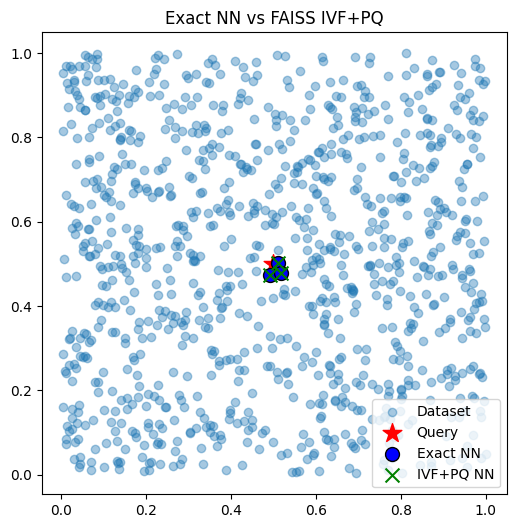

In [8]:
# Visualize
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Flat NN -> Exact NN
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# IVF+PQ NN -> FAISS
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Exact NN vs FAISS IVF+PQ")
plt.show()